In [1]:

import os
import pandas as pd

folder_path = r"C:\Users\user\Downloads\UTKFace"

data = []

for filename in os.listdir(folder_path):
    if filename.lower().endswith(".jpg"):
        try:
            age = int(filename.split("_")[0])

            if 0 <= age <= 12:
                age_group = 0
            elif age <= 19:
                age_group = 1
            elif age <= 35:
                age_group = 2
            elif age <= 60:
                age_group = 3
            else:
                age_group = 4

            data.append({
                "filename": filename,
                "age": age,
                "age_group": age_group
            })
        except (ValueError, IndexError):
            continue

df = pd.DataFrame(data)

print("Total images:", len(df))
print("\nAge group distribution:")
print(df["age_group"].value_counts().sort_index())


Total images: 23708

Age group distribution:
age_group
0     3413
1     1180
2    10514
3     6204
4     2397
Name: count, dtype: int64


In [1]:
import os

folder_path = r"C:\Users\user\Downloads\UTKFace"

jpg_count = 0
jpeg_count = 0
png_count = 0

for filename in os.listdir(folder_path):
    if filename.lower().endswith(".jpg"):
        jpg_count += 1
    elif filename.lower().endswith(".jpeg"):
        jpeg_count += 1
    elif filename.lower().endswith(".png"):
        png_count += 1

print("JPG images:", jpg_count)
print("JPEG images:", jpeg_count)
print("PNG images:", png_count)
print("Total images:", jpg_count + jpeg_count + png_count)

JPG images: 23708
JPEG images: 0
PNG images: 0
Total images: 23708


In [2]:

import os
import pandas as pd

# Dataset folder
folder_path = r"C:\Users\user\Downloads\UTKFace"

data = []

# Read image filenames and extract actual ages
for filename in os.listdir(folder_path):
    if filename.lower().endswith(".jpg"):
        try:
            age = int(filename.split("_")[0])

            data.append({
                "filename": filename,
                "age": age
            })

        except (ValueError, IndexError):
            continue

# Create DataFrame
df = pd.DataFrame(data)

# Dataset statistics
print("Total images:", len(df))

print("\nFirst 5 rows:")
print(df.head())

print("\nAge statistics:")
print(df["age"].describe())

print("\nMinimum age:", df["age"].min())
print("Maximum age:", df["age"].max())
print("Average age:", round(df["age"].mean(), 2))
print("Median age:", df["age"].median())


Total images: 23708

First 5 rows:
                        filename  age
0  100_0_0_20170112213500903.jpg  100
1  100_0_0_20170112215240346.jpg  100
2  100_1_0_20170110183726390.jpg  100
3  100_1_0_20170112213001988.jpg  100
4  100_1_0_20170112213303693.jpg  100

Age statistics:
count    23708.000000
mean        33.303484
std         19.886112
min          1.000000
25%         23.000000
50%         29.000000
75%         45.000000
max        116.000000
Name: age, dtype: float64

Minimum age: 1
Maximum age: 116
Average age: 33.3
Median age: 29.0


In [4]:

import tensorflow as tf
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from sklearn.model_selection import train_test_split

tf.keras.utils.set_random_seed(42)

# -----------------------------
# Configuration
# -----------------------------
IMG_SIZE = (48, 48)
BATCH_SIZE = 64

folder_path = r"C:\Users\user\Downloads\UTKFace"

# -----------------------------
# Extract filenames and ages
# -----------------------------
data = []

for filename in os.listdir(folder_path):
    if filename.lower().endswith(".jpg"):
        try:
            age = int(filename.split("_")[0])

            if 0 <= age <= 116:
                data.append({
                    "filepath": os.path.join(folder_path, filename),
                    "age": float(age)
                })

        except (ValueError, IndexError):
            continue

df = pd.DataFrame(data)

print("Total images:", len(df))
print("\nAge statistics:")
print(df["age"].describe())

# -----------------------------
# Split dataset: 80% train,
# 10% validation, 10% test
# -----------------------------
train_df, temp_df = train_test_split(
    df,
    test_size=0.20,
    random_state=42
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    random_state=42
)

print("\nTraining images:", len(train_df))
print("Validation images:", len(val_df))
print("Testing images:", len(test_df))

# -----------------------------
# Load and preprocess images
# -----------------------------
def load_image(filepath, age):
    image = tf.io.read_file(filepath)

    image = tf.io.decode_jpeg(
        image,
        channels=1
    )

    image = tf.image.resize(
        image,
        IMG_SIZE
    )

    image = tf.cast(image, tf.float32) / 255.0

    return image, tf.cast(age, tf.float32)

# -----------------------------
# Create TensorFlow datasets
# -----------------------------
def create_dataset(dataframe, shuffle=False):
    paths = dataframe["filepath"].to_numpy()
    ages = dataframe["age"].to_numpy(dtype=np.float32)

    dataset = tf.data.Dataset.from_tensor_slices(
        (paths, ages)
    )

    if shuffle:
        dataset = dataset.shuffle(
            buffer_size=len(dataframe),
            seed=42
        )

    dataset = dataset.map(
        load_image,
        num_parallel_calls=tf.data.AUTOTUNE
    )

    dataset = dataset.batch(BATCH_SIZE)
    dataset = dataset.prefetch(tf.data.AUTOTUNE)

    return dataset

train_data = create_dataset(train_df, shuffle=True)
val_data = create_dataset(val_df)
test_data = create_dataset(test_df)

# -----------------------------
# Check one batch
# -----------------------------
for images, ages in train_data.take(1):
    print("\nImage batch shape:", images.shape)
    print("Age labels shape:", ages.shape)
    print("Example ages:", ages[:10].numpy())


Total images: 23708

Age statistics:
count    23708.000000
mean        33.303484
std         19.886112
min          1.000000
25%         23.000000
50%         29.000000
75%         45.000000
max        116.000000
Name: age, dtype: float64

Training images: 18966
Validation images: 2371
Testing images: 2371

Image batch shape: (64, 48, 48, 1)
Age labels shape: (64,)
Example ages: [24. 26. 26. 19. 38. 18. 39. 14. 54.  5.]


In [6]:
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.model_selection import train_test_split

from keras.callbacks import EarlyStopping
from keras.models import Sequential
from keras.layers import Dense, Input, Activation, Flatten, Conv2D, MaxPool2D
from keras.utils import to_categorical

from sklearn.metrics import accuracy_score, confusion_matrix, classification_report


In [17]:

model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(48, 48, 1)),
    tf.keras.layers.Flatten(),

    tf.keras.layers.Dense(128, activation="relu"),
    tf.keras.layers.Dense(64, activation="relu"),

    # One numerical age prediction
    tf.keras.layers.Dense(1, activation="linear")
])

model.compile(
    optimizer="adam",
    loss="mse",
    metrics=["mae"]
)

model.summary()


Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_3 (Flatten)             │ (None, 2304)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 128)            │       295,040 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 303,361 (1.16 MB)

 Trainable params: 303,361 (1.16 MB)

 Non-trainable params: 0 (0.00 B)

In [16]:
print("Model output shape:", model.output_shape)

for images, ages in train_data.take(1):
    predictions = model(images)
    print("Predictions shape:", predictions.shape)
    print("Age labels shape:", ages.shape)

Model output shape: (None, 5)
Predictions shape: (64, 5)
Age labels shape: (64,)


In [18]:
early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

history = model.fit(
    train_data,
    validation_data=val_data,
    epochs=15,
    callbacks=[early_stopping]
)


Epoch 1/30
297/297 ━━━━━━━━━━━━━━━━━━━━ 10s 29ms/step - loss: 437.6639 - mae: 15.9982 - val_loss: 330.7348 - val_mae: 14.1756
Epoch 2/30
297/297 ━━━━━━━━━━━━━━━━━━━━ 7s 22ms/step - loss: 298.4568 - mae: 13.2368 - val_loss: 267.7286 - val_mae: 12.4531
Epoch 3/30
297/297 ━━━━━━━━━━━━━━━━━━━━ 8s 26ms/step - loss: 251.1524 - mae: 11.9555 - val_loss: 237.1293 - val_mae: 11.6393
Epoch 4/30
297/297 ━━━━━━━━━━━━━━━━━━━━ 11s 36ms/step - loss: 237.3483 - mae: 11.5045 - val_loss: 234.3172 - val_mae: 11.6624
Epoch 5/30
297/297 ━━━━━━━━━━━━━━━━━━━━ 12s 41ms/step - loss: 237.0305 - mae: 11.4722 - val_loss: 228.8134 - val_mae: 11.5355
Epoch 6/30
297/297 ━━━━━━━━━━━━━━━━━━━━ 9s 31ms/step - loss: 211.1194 - mae: 10.7565 - val_loss: 205.6994 - val_mae: 10.4515
Epoch 7/30
297/297 ━━━━━━━━━━━━━━━━━━━━ 8s 28ms/step - loss: 208.6379 - mae: 10.6335 - val_loss: 209.3503 - val_mae: 10.8613
Epoch 8/30
297/297 ━━━━━━━━━━━━━━━━━━━━ 9s 29ms/step - loss: 198.2384 - mae: 10.3937 - val_loss: 202.7972 - val_mae: 10.25

In [19]:
test_loss, test_accuracy = model.evaluate(test_data)

print("\nTest loss:", test_loss)
print("Test accuracy:", test_accuracy)


38/38 ━━━━━━━━━━━━━━━━━━━━ 1s 33ms/step - loss: 163.2891 - mae: 9.1893

Test loss: 163.28909301757812
Test accuracy: 9.189305305480957


In [20]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Store actual and predicted ages
actual_ages = []
predicted_ages = []

for images, ages in test_data:
    predictions = model.predict(images, verbose=0)

    actual_ages.extend(ages.numpy().reshape(-1))
    predicted_ages.extend(predictions.reshape(-1))

actual_ages = np.array(actual_ages)
predicted_ages = np.array(predicted_ages)

# Create error analysis DataFrame
error_df = pd.DataFrame({
    "Actual Age": actual_ages,
    "Predicted Age": predicted_ages
})

error_df["Error"] = (
    error_df["Predicted Age"] - error_df["Actual Age"]
)

error_df["Absolute Error"] = error_df["Error"].abs()

# Sort by largest prediction errors
error_df = error_df.sort_values(
    by="Absolute Error",
    ascending=False
).reset_index(drop=True)

print("Test images:", len(error_df))
print("Test MAE:", round(error_df["Absolute Error"].mean(), 2), "years")
print("\n10 Largest Prediction Errors:")
print(error_df.head(10).round(2))

Test images: 2371
Test MAE: 9.19 years

10 Largest Prediction Errors:
   Actual Age  Predicted Age      Error  Absolute Error
0         1.0      69.300003  68.300003       68.300003
1         1.0      62.950001  61.950001       61.950001
2        76.0      17.410000 -58.590000       58.590000
3       111.0      53.400002 -57.599998       57.599998
4        90.0      34.279999 -55.720001       55.720001
5        90.0      34.650002 -55.349998       55.349998
6        80.0      25.610001 -54.389999       54.389999
7        89.0      35.709999 -53.290001       53.290001
8        69.0      15.730000 -53.270000       53.270000
9        64.0      10.910000 -53.090000       53.090000


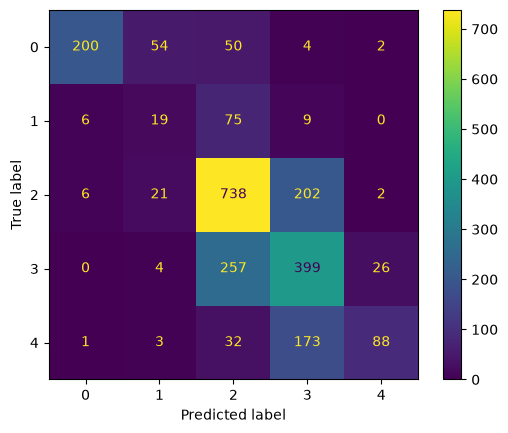

In [29]:

import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

# Collect actual and predicted ages
actual_ages = []
predicted_ages = []

for images, ages in test_data:
    predictions = model.predict(images, verbose=0)

    actual_ages.extend(ages.numpy().reshape(-1))
    predicted_ages.extend(predictions.reshape(-1))

actual_ages = np.array(actual_ages)
predicted_ages = np.array(predicted_ages)

# Convert ages into groups for the confusion matrix
def age_to_group(ages):
    return np.digitize(ages, bins=[12, 19, 35, 60])

actual_groups = age_to_group(actual_ages)
predicted_groups = age_to_group(predicted_ages)

age_group_names = [
    "0–12",
    "13–19",
    "20–35",
    "36–60",
    "61+"
]

# Display confusion matrix
ConfusionMatrixDisplay.from_predictions(
    actual_groups,
    predicted_groups,
    
)

